[![Mở trong Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thanhmk/kinhteluong/blob/main/KTL%20T%C3%A0i%20ch%C3%ADnh/Module_5/B4_GARCH_trong_khung_khong_gian_trang_thai.ipynb)

In [ ]:
# Chuẩn bị môi trường trên Colab (chạy ô này một lần trước khi chạy các ô khác)
import os, urllib.request, urllib.parse

print("Bài này không cần tải dữ liệu.")

## KINH TẾ LƯỢNG TÀI CHÍNH
MODULE 5 | BÀI 4

---

# **MÔ HÌNH GARCH TRONG KHUNG MÔ HÌNH KHÔNG GIAN TRẠNG THÁI**

|  |  |
|:---|:---|
|**Thời gian đọc** | 60 phút |
|**Kiến thức nền** | Phân tích chuỗi thời gian, GARCH |
|**Từ khóa** | Mô hình không gian trạng thái, quá trình Markov, bộ lọc Kalman |


---

*Trong bài này, ta sẽ dùng cách tiếp cận không gian trạng thái để tạo mô hình GARCH. Mô hình không gian trạng thái (SSM) ban đầu được phát triển như một phương pháp phân tích cho nghiên cứu liên quan đến hàng không vũ trụ. Tuy nhiên, gần đây nó thu hút nhiều quan tâm trong kỹ thuật và tài chính. Ta sẽ mô tả ngắn gọn cấu trúc của mô hình không gian trạng thái và các tính chất của nó. Sau đó ta sẽ giới thiệu một mô hình không gian trạng thái tuyến tính phổ biến: bộ lọc Kalman. Ta sẽ đi qua các kiến thức cơ bản của bộ lọc Kalman. Cuối cùng, ta sẽ kết hợp bộ lọc Kalman với mô hình GARCH(1,1) để bạn hiểu mô hình kết hợp hoạt động thế nào.*

## **1. Mô hình không gian trạng thái**

### **1.1. Cơ bản về mô hình không gian trạng thái**

Mô hình không gian trạng thái (hay mô hình tuyến tính động, DLM) là một lớp mô hình chuỗi thời gian phổ biến khác. Mô hình không gian trạng thái (SSM) cho rằng có hai loại biến chuỗi thời gian: loại ta quan sát được và loại ta không quan sát được. Loại ta không quan sát được gọi là **trạng thái (states)**. Loại ta quan sát được thì gọi là **quan sát (observations)**. Các trạng thái được sinh ra bởi một hệ thống mô tả trạng thái tiến hóa theo thời gian ra sao. Ta muốn tìm ra cấu trúc của hệ thống này. Tuy nhiên, ta chỉ thấy các quan sát. Các quan sát phụ thuộc vào trạng thái cộng thêm nhiễu. Ta dùng một phương trình quan sát để mô tả quan hệ giữa quan sát và trạng thái. Ta cũng thêm một nhiễu đo lường vào phương trình quan sát để lấp khoảng cách giữa quan sát và trạng thái. Ta có thể hình thức hóa khái niệm trên bằng các phương trình sau. Giả sử $y_{t}$ là biến quan sát của chuỗi thời gian và $x_{t}$ là biến trạng thái của chuỗi thời gian:

**Phương trình quan sát:** $\hspace{3cm}  y_{t} = A_{t}x_{t} + v_{t}, \quad v_{t} \sim WN(0, V_{t}) \hspace{4cm} (1)$

trong đó $v_{t}$ là nhiễu đo lường.

**Phương trình trạng thái:** $\hspace{4.3cm}  x_{t} = \Phi_{t} x_{t-1} + w_{t}, \quad w_{t} \sim WN(0,W_{t}) \hspace{3.2cm}  (2)$

trong đó $w_{t}$ là nhiễu hệ thống.

Ta cũng giả định $v_{t}$ và $v_{s}$ độc lập khi $t\neq s$, $w_{t}$ và $w_{s}$ độc lập khi $t\neq s$, và $v_{t}$ và $w_{s}$ không tương quan ở mọi độ trễ.

Hai phương trình trên tạo thành nền tảng của mô hình không gian trạng thái. Ta cũng có thể dùng đồ thị sau để minh họa cấu trúc của mô hình không gian trạng thái.

**Hình 1: Quan hệ giữa trạng thái và quan sát trong mô hình không gian trạng thái**

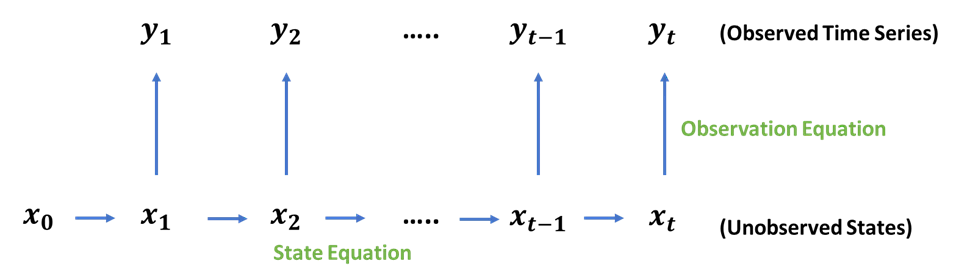

Từ hình 1, ta thấy sự tiến hóa của biến trạng thái được biểu diễn bởi một phương trình trạng thái. Đây là hệ thống hay mô hình được tạo ra từ lý thuyết hoặc quy trình. Phương trình trạng thái có thể là một phương trình đơn hoặc một tập phương trình để mô tả cách các trạng thái được sinh ra. Sau đó, ta có phương trình quan sát để nối các trạng thái từ phương trình trạng thái với các quan sát bằng một nhiễu đo lường. Về số lượng biến trạng thái và biến quan sát, trong một mô hình không gian trạng thái có thể có nhiều hơn một biến trạng thái hoặc biến quan sát. Số biến trạng thái cũng không nhất thiết bằng số biến quan sát. Về thiết kế mô hình không gian trạng thái, nó có thể tuyến tính hoặc phi tuyến. Trong phương trình (1) và phương trình (2), ta thấy $A_{t}$ và $\Phi_{t}$ đều có chỉ số thời gian. Nghĩa là chúng có thể thay đổi theo thời gian. Nếu vậy, đó là mô hình không gian trạng thái biến thiên theo thời gian. Nếu $A_{t}$ và $\Phi_{t}$ cố định bất kể thời gian (không có chỉ số thời gian), đó là mô hình không gian trạng thái bất biến theo thời gian.

Ta thấy mô hình không gian trạng thái là một dạng mô hình hóa chuỗi thời gian rất tổng quát và linh hoạt. Bạn có thể xây dựng một mô hình chuỗi thời gian cho phương trình trạng thái rồi thêm một phương trình quan sát để nối các trạng thái với quan sát hay dữ liệu.

Khi đã xây dựng một mô hình không gian trạng thái, ta sẽ dùng mô hình để đạt ba mục tiêu sau:

> **a. Dự báo (Predicting):** dự báo các giá trị tương lai của trạng thái cho trước mọi thông tin và dữ liệu ta có hôm nay <br>
> **b. Lọc (Filtering):** ước lượng các giá trị hiện tại của trạng thái cho trước mọi thông tin và dữ liệu ta có hôm nay <br>
> **c. Làm trơn (Smoothing):** ước lượng các giá trị quá khứ của trạng thái cho trước mọi thông tin và dữ liệu ta có hôm nay  <br>

### **1.2. Các tính chất của mô hình không gian trạng thái**

Bây giờ hãy xem hai tính chất chính của mô hình không gian trạng thái.

**a. $x_{t}$ là quá trình Markov**

Nghĩa là $P(x_{t} | x_{t-1}, x_{t-2}, \cdots, x_{0}) = P(x_{t} | x_{t-1})$. Quá trình Markov cho rằng xác suất của giá trị trạng thái ở thời điểm hiện tại chỉ phụ thuộc vào giá trị của trạng thái gần nhất. Giá trị của trạng thái ở các thời điểm cũ hơn không ảnh hưởng đến giá trị hôm nay. Ta có thể nói $x_{t}$ không có bộ nhớ.

**b. $y_{t}$ được xác định đầy đủ khi cho trước $x_{t}$**

Phát biểu này có thể biểu diễn như sau: $P(y_{t} | x_{t}, x_{t-1}, \cdots, x_{0}; \ y_{t-1}, y_{t-2}, \cdots, y_{1}) = P(y_{t} | x_{t})$.

Với hai tính chất trên, ta có thể viết hàm phân phối đồng thời cho trạng thái và quan sát như sau:

$$ P(x_{0:t},y_{1:t}) = P(x_{0}) \prod_{i=1}^{t} P(x_{i}|x_{i-1}) P(y_{i}|x_{i}) $$

Với $x_{0}$, ta thường phải giả định giá trị hoặc phân phối của nó để tiếp tục xây dựng mô hình.

### **1.3 Lợi ích của mô hình không gian trạng thái (SSM)**

Có một số lý do khiến mô hình hóa không gian trạng thái ngày càng phổ biến giữa các nhà nghiên cứu. Thứ nhất, theo các tính chất ta đã giải thích ở trên, ta chỉ cần thông tin gần nhất để ước lượng giá trị của trạng thái hiện tại. Tính chất này giảm lượng dữ liệu lịch sử cần thiết và dung lượng lưu trữ dữ liệu cần để ước lượng SSM.

Thứ hai, như ta thấy ở trên, SSM cho phép các hệ số biến thiên theo thời gian. Điều này rất hữu ích nếu giai đoạn mô hình hóa tình cờ có thay đổi chế độ. SSM biến thiên theo thời gian rất tốt để nắm bắt thay đổi này.

Các ưu điểm khác của SSM gồm:

> a. Dùng SSM để xử lý giá trị thiếu bằng hàm dự báo. <br>
> b. Áp dụng SSM để xây dựng mô hình cho các hệ thống đa biến phức tạp. <br>
> c. Dùng SSM để xây dựng mô hình cho chuỗi thời gian không dừng. <br>

Ở mục tiếp theo, ta sẽ giới thiệu bộ lọc Kalman. Bộ lọc Kalman là mô hình không gian trạng thái được nghiên cứu nhiều nhất, và ta sẽ dùng bộ lọc Kalman làm mô hình không gian trạng thái cơ sở để xây dựng mô hình GARCH(1,1).

### **1.4. Ước lượng tham số cho mô hình không gian trạng thái**

Khi mô hình không gian trạng thái đã được đặc tả, ta có thể ước lượng các hệ số. Ta phải ước lượng các tham số sau: $A_{t}, \Phi_{t}, V_{t}$ và $W_{t}$.

Phương pháp ước lượng phổ biến nhất là MLE. Tuy nhiên, ước lượng Bayes cũng là một lựa chọn khả thi khác để ước lượng tham số. Thực ra, ước lượng Bayes là cách tiếp cận phù hợp cho mô hình không gian trạng thái vì bản chất bài toán của SSM là ước lượng giá trị của các trạng thái cho trước mọi quan sát ta biết. Thật vậy, ta sẽ dùng cách tiếp cận Bayes để bàn chủ đề tiếp theo: bộ lọc Kalman.

## **2. Bộ lọc Kalman**

### **2.1. Thiết lập mô hình bộ lọc Kalman**

Bộ lọc Kalman là một mô hình không gian trạng thái tuyến tính với nhiễu chuẩn (Gauss). Nó rất phổ biến nhờ phương pháp đệ quy có thể tránh các vấn đề tính toán nặng và lưu trữ xảy ra với các phương pháp phân tích thống kê khác. Trong mục này, ta sẽ nghiên cứu mô hình bộ lọc Kalman đa biến bất biến theo thời gian. Các tính chất của bộ lọc Kalman suy ra trong mục này vẫn áp dụng cho các mô hình bộ lọc Kalman có một số hoặc tất cả tham số biến thiên theo thời gian. Hãy viết ra mô hình và bàn về các tính chất của nó.

Giả sử ta có $x_t$ là vectơ trạng thái $r\times 1$ và $y_t$ là vectơ quan sát $n\times 1$. Mô hình có thể viết như sau:

**Phương trình quan sát:** $y_{t} = F' x_{t} + v_{t}, \ \ v_{t}$ là nhiễu đo lường.

**Phương trình trạng thái:** $x_{t} = G x_{t-1} + w_{t}, \ \ w_{t}$ là nhiễu hệ thống.   

trong đó $v_{t} \sim N(0,V)$  và  $w_{t} \sim N(0,W)$.

Ta cũng giả định giá trị ban đầu của $x_{t}$ là $x_{0}$ và $x_{0}$ có phân phối $x_{0} \sim N(m_{0},C_{0})$ với $m_{0}$ và $C_{0}$ đã biết.

Theo giả định ở mục trước, ta vẫn giả định $v_{t}$ và $v_{s}$ độc lập khi $t \neq s, \ w_{t}$ và $w_{s}$ độc lập khi $t \neq s$, và $v_{t}$ và $w_{s}$ không tương quan ở mọi độ trễ.

Trong mô hình, $F$ là ma trận $r \times n$, và gọi là ma trận quan sát hay ma trận thiết kế. $G$ là ma trận $r \times r$ và gọi là ma trận chuyển trạng thái.

Với nhiều biến ta đã nhắc đến, ta sẽ tóm tắt các biến này trong danh sách sau:

> $x_{t}$: vectơ trạng thái $r \times 1$ tại thời điểm $t$; <br>
> $y_{t}$: vectơ quan sát $n \times 1$ tại thời điểm $t$; <br>
> $F$: ma trận quan sát $r \times n$ giữa quan sát và trạng thái tại thời điểm $t$; <br>
> $G$: ma trận chuyển trạng thái $r \times r$ giữa trạng thái hiện tại tại $t$ và trạng thái trước tại $t-1$; <br>
> $v_{t}$: nhiễu đo lường từ phân phối chuẩn đa biến; <br>
> $w_{t}$: nhiễu hệ thống từ phân phối chuẩn đa biến; <br>
> $V$: ma trận phương sai-hiệp phương sai của phân phối chuẩn đa biến mà nhiễu đo lường lấy từ đó; <br>
> $W$: ma trận phương sai-hiệp phương sai của phân phối chuẩn đa biến mà nhiễu hệ thống lấy từ đó; <br>
> $m_{0}$: giá trị trung bình của phân phối chuẩn đa biến của trạng thái ban đầu, $x_{0}$; <br>
> $C_{0}$: ma trận phương sai-hiệp phương sai của phân phối chuẩn đa biến của trạng thái ban đầu, $x_{0}$.  <br>

### **2.2. Suy ra mô hình bộ lọc Kalman**

Ở mục trước, ta đã đi qua phần thiết lập mô hình bộ lọc Kalman và mô tả mọi biến trong mô hình này. Trong mục này, ta sẽ giải thích mô hình bộ lọc Kalman hoạt động thế nào và các kết quả chính của mô hình. Ta sẽ dùng cách tiếp cận Bayes để giải thích mô hình bộ lọc Kalman hoạt động ra sao.

Ở mục trước, ta đã nhắc rằng khái niệm dùng mọi thông tin từ quá khứ và dữ liệu mới để suy ra trạng thái không quan sát được trong mô hình không gian trạng thái rất giống quá trình cập nhật Bayes. Hãy thử minh họa mô hình không gian trạng thái tìm kiếm điều gì theo định lý Bayes.

Với mô hình bộ lọc Kalman, ta có thể biểu diễn bằng công thức định lý Bayes sau.

$$ P(x_{t}|y_{t}, D_{t-1}) = \frac{P(y_{t}|x_{t})P(x_{t}|D_{t-1})}{P(y_{t})} $$

Trong đó $x_{t}$ là trạng thái hiện tại, $y_{t}$ là quan sát hiện tại, $D_{t-1}$ là mọi thông tin quá khứ, gồm các trạng thái quá khứ và các quan sát quá khứ.

Sau đây là phân tích xác suất tiên nghiệm, hàm hợp lý và xác suất hậu nghiệm.

> Xác suất hậu nghiệm: $P(x_{t}|y_{t},D_{t-1})$ <br>
> Hàm hợp lý: $P(y_{t}|x_{t})$ <br>
> Xác suất tiên nghiệm: $P(x_{t}|D_{t-1})$ <br>

Phương trình trên nói rằng xác suất có được giá trị trạng thái $x_{t}$ tại thời điểm $t$, cho trước ta biết quan sát hiện tại $y_{t}$ và mọi hiểu biết trước đó $D_{t-1}$, là tích của khả năng $y_{t}$ xảy ra cho trước $x_{t}$ và xác suất trạng thái $x_{t}$ xảy ra cho trước mọi hiểu biết trước đó $D_{t_1}$. Ta cũng chuẩn hóa tích này bằng cách chia cho xác suất $y_{t}$ xảy ra. Đây là quá trình cập nhật giá trị của trạng thái hiện tại $x_{t}$ bằng thông tin mới $y_{t}$.

Với phương trình Bayes trên và một số biến đổi toán học, ta có thể suy ra các kết quả sau:

> **Tiên nghiệm:**  $ x_{t}|D_{t-1} = x_{t}|y_{1:t-1} \sim N(a_{t},R_{t}) $ <br>
> Trong đó $a_{t} = G m_{t-1}$ và $R_{t} = G' C_{t-1} G + W$ <br>

> **Hàm hợp lý:** $ y_{t}|x_{t} \sim N(F x_{t},V) $

> **Dự báo một bước:**  $ y_{t}|y_{t-1} \sim N(f_{t},Q_{t}) $ <br>
> Trong đó $f_{t} = Fa_{t}$ và $Q_{t} = F' R_{t}F + V$

> **Hậu nghiệm:** $ x_{t}|D_{t} = x_{t}|y_{1:t} \sim N(m_{t},C_{t}) $ <br>
> Trong đó 
> $m_{t} = a_{t} + K_{t} e_{t}$ <br>
> $C_{t} = R_{t} - K_{t}' Q_{t} K_{t} =(1-K_{t}F)R_{t}$ <br>
> $K_{t} = R_{t} F Q_{t}^{-1}$  ($K_{t}$ gọi là ma trận độ lợi Kalman) <br>
> $e_{t} = y_{t} - f_{t}$ và $e_{t} \sim N(0,Q_{t})$ <br>


Kết quả hậu nghiệm trên gọi là đệ quy bộ lọc Kalman. Hãy nhớ có ba mục tiêu của mô hình không gian trạng thái đã mô tả trước. Kết quả này nhằm đạt mục tiêu lọc: Dùng mọi thông tin quá khứ và dữ liệu mới để ước lượng giá trị hiện tại của trạng thái. Ta dùng trung bình của phân phối hậu nghiệm $m_{t}$ làm giá trị ước lượng của trạng thái hiện tại $x_{t}$, cho trước mọi thông tin ta có.

Hãy xem kết quả trên một cách trực giác. Nhìn vào trung bình của phương trình hậu nghiệm, ta thấy $m_{t}$ là tổ hợp tuyến tính của trạng thái trước $m_{t-1}$ và thông tin mới $y_{t}$. Ta có thể xem giá trị ước lượng của trạng thái hiện tại là trung bình có trọng số của giá trị trạng thái quá khứ và thông tin mới. $K_{t}$ (ma trận độ lợi Kalman) là một trong các trọng số trong công thức $m_{t}$. Ta có thể xem $K_{t}$ như một hệ số điều chỉnh để quyết định có nên đặt nhiều trọng số hơn vào thông tin mới hay không. Giá trị $K_{t}$ càng cao, mô hình càng đặt nhiều trọng số vào thông tin mới. Ngoài ra, trạng thái hiện tại ước lượng chỉ phụ thuộc vào giá trị trạng thái kỳ trước và giá trị mới; không cần có mọi dữ liệu lịch sử để cập nhật trạng thái hiện tại. Phương pháp đệ quy cập nhật giá trị trạng thái hiện tại bằng thông tin mới và chỉ trạng thái kỳ trước làm cho dự báo của bộ lọc Kalman dễ hơn nhiều so với các phương pháp khác.

### **2.3 Dự báo bằng bộ lọc Kalman**

Một lý do chính để học bộ lọc Kalman là dùng nó để dự báo. Dự báo gồm dự đoán $x_{t+d}$ và $y_{t+d}$ cho trước $y_{1:t}$. Ta có thể áp dụng kết quả từ mục trước để dự báo.

Khi $d = 1$, kết quả dự báo có thể suy ra từ các phương trình tiên nghiệm và dự báo một bước ở mục trước.

> **Trạng thái tại $t+1$:** <br>
> $x_{t+1} = Gm_{t}$ trạng thái dự báo <br>
> $R_{t+1}  =G' C_{t}G + W$ phương sai dự báo của trạng thái <br>

> **Quan sát tại $t+1$:** <br>
> $y_{t+1} = F x_{t+1}$ quan sát dự báo <br>
> $Q_{t+1} = F' R_{t+1}F + V$ phương sai dự báo của quan sát <br>

<br>
Khi $d > 1$, ta có thể dùng phương pháp đệ quy để có kết quả như sau:

> **Trạng thái tại $t+d$:** <br>
> $x_{t+d} = Gm_{t+d-1}$  trạng thái dự báo <br>
> $R_{t+d} = G' C_{t+d-1}G + W$ phương sai dự báo của trạng thái <br>

> **Quan sát tại $t+d$:** <br>
> $y_{t+d} = F x_{t+d}$ quan sát dự báo <br>
> $Q_{t+d} = F' R_{t+d}F + V$ phương sai dự báo của quan sát <br>

## **3. Dùng bộ lọc Kalman để khớp mô hình GARCH(1,1)**

Trong mục này, ta sẽ áp dụng bộ lọc Kalman để xây dựng mô hình GARCH(1,1). Ta đã học ở các bài trước rằng mô hình GARCH có đặc điểm phương sai thay đổi có điều kiện ở mức quan sát. Do đó, ta cần đưa đặc điểm này vào mô hình bộ lọc Kalman. Ta có thể viết mô hình như sau:

$$ \begin{align*}
  y_{t}  &= F x_{t} + z_{t} \\
  x_{t}  &= G x_{t-1} + w_{t}, \text{ trong đó } w_{t} \sim N(0,W) \\
  z_{t}  &= s_{t} \epsilon_{t}, \text{ trong đó } \epsilon_{t} \sim N(0,1) \\
  s_{t}^{2}  &= \alpha_{0} + \alpha_{1} z_{t-1}^{2} + \beta_{1} s_{t-1}^{2}
\end{align*} $$

Hai phương trình đầu trong hệ phương trình trên là từ bộ lọc Kalman. Phương trình đầu là phương trình quan sát và phương trình thứ hai là phương trình trạng thái. Trong phương trình quan sát, ta thấy nhiễu đo lường có đặc tả thêm từ phương trình thứ ba và thứ tư. Phương trình thứ ba và thứ tư là phần cho GARCH. Nhiễu đo lường bây giờ tuân theo thiết lập GARCH(1,1) chuẩn tắc.

Từ hệ phương trình trên cho mô hình bộ lọc Kalman-GARCH(1,1), ta có thể biến đổi và thu được kết quả hậu nghiệm và dự báo một bước.

> **Hậu nghiệm cho trạng thái:**  $ x_{t}|y_{1:t} \sim N(m_{t},C_{t}) $  <br>
> Trong đó mọi tham số giống mô hình bộ lọc Kalman chuẩn

> **Dự báo một bước cho quan sát:**  $ y_{t}|y_{t-1} \sim N(f_{t},Q_{t}) $  <br>
> Trong đó $f_{t} = Fa_{t}$ và $Q_{t} = F' R_{t} F + s_{t}^{2}$

Từ kết quả trên, ta thấy khác biệt duy nhất giữa mô hình bộ lọc Kalman chuẩn và mô hình bộ lọc Kalman-GARCH(1,1) là $s_{t}^{2}$ trong $Q_{t}$, phương sai của quan sát.

Khi đã có các phương trình hậu nghiệm và dự báo một bước, ta có thể dùng lấy mẫu Gibbs hoặc phương pháp lấy mẫu Metropolis-Hasting để lấy mẫu các tham số chưa biết. Với các vectơ trạng thái chưa biết, ta dùng một kỹ thuật gọi là lọc xuôi và lấy mẫu ngược (forward filtering and backward sampling, FFBS) để lấy mẫu. FFBS do Carter và Kohn cũng như Fruhwirth-Schnatter đề xuất. Hầu hết phần mềm thống kê đều có hàm lấy mẫu FFBS để dùng. Để biết thêm về cách lấy mẫu, Omar trình bày các bước chi tiết để lấy mẫu phân phối tiên nghiệm và mô phỏng dữ liệu bằng FFBS trên mô hình bộ lọc Kalman GARCH(1,1).

## **4. Kết luận**

Trong bài này, ta đã đi qua lý thuyết của mô hình không gian trạng thái. Ta đã nói về kiến thức cơ bản của mô hình không gian trạng thái, các tính chất, lợi ích và phương pháp ước lượng của nó. Sau đó ta bàn về một mô hình không gian trạng thái tuyến tính phổ biến, bộ lọc Kalman. Ta giải thích bộ lọc Kalman hoạt động thế nào, cách suy ra mô hình và cách dùng nó để dự báo. Sau khi học bộ lọc Kalman, ta kết hợp bộ lọc Kalman với mô hình GARCH(1,1) và đưa ra phần thiết lập mô hình ngắn gọn cho mô hình bộ lọc Kalman-GARCH(1,1). Bài này khép lại phần nghiên cứu của ta về phương sai thay đổi có điều kiện trong dữ liệu chuỗi thời gian. Ở module tiếp theo, ta sẽ đi sâu vào phương pháp kiểm tra tính dừng của một chuỗi thời gian. Ta cũng sẽ xem xét quan hệ giữa hai chuỗi thời gian.

## **Tài liệu tham khảo**

- Carter, Chris, and Robert Kohn. "On Gibbs Sampling for State Space Models." Biometrika, vol. 81, 1994, pp. 541–553.

- Fruhwirth-Schnatter, Sylvia. "Data Augmentation and Dynamic Linear Models." Journal of Time Series Analysis, vol. 15, 1994, pp. 183–202.

- Omar, Zayd. State-Space Models with GARCH Errors: Application to Health Data. 2019. McGill University, Master's thesis.